# From one line to a hidden layer

A neural network is built from one simple part, repeated: a **unit** (or
neuron) that takes a weighted sum of its inputs, adds a bias, and squashes the
result. Lesson 4's logistic regression is exactly one such unit. This notebook
asks what one unit can do, what it cannot, and what changes when several
units sit side by side in a **hidden layer**.

Two problems from Meridian Instruments, a fictional maker of optical sensors:

1. an **acceptance test**: each sensor is measured on two calibration axes,
   and passes when both offsets are *jointly* small;
2. a **two-channel drift**: a sensor is correctable when its two channels
   drift the *same* way, and not when they drift opposite ways.

By the end you will have seen one straight line fail on both, a two-unit
network written down by hand solve the second, and scikit-learn's
`MLPClassifier` learn both, with a boundary that grows as hidden units are
added.

## 1. Setup

In [1]:
# Everything used here ships with the course image:
# pip install numpy==1.26.4 pandas==2.1.1 matplotlib==3.8.0 scikit-learn==1.3.1

import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

from instrument_data import (make_acceptance_test, make_channel_drift,
                             TRUE_ACCEPT_RADIUS_SIGMA, TRUE_RIG_ERROR_RATE)

# MLPClassifier warns when it stops at max_iter; the runs below are long enough.
warnings.filterwarnings("ignore", message="Stochastic Optimizer")

FIGURES = Path.cwd().parent / "Figures"
FIGURES.mkdir(exist_ok=True)
BLUE, TEAL, RUST, GOLD, SLATE = "#1F4E79", "#2E8B8B", "#B4483E", "#C9A227", "#4A5568"

units = make_acceptance_test()
print(f"{len(units)} sensors, 2 measurements each")
print(f"recorded as accepted     : {units.accepted.mean():.4f}")
print(f"verdicts the rig got wrong: "
      f"{(units.accepted != units.truly_within_tolerance).mean():.4f}")

3000 sensors, 2 measurements each
recorded as accepted     : 0.5473
verdicts the rig got wrong: 0.0330


## 2. The acceptance test, looked at first

Split before looking (lesson 1), and standardise each axis with a scaler fitted
on the training part only (lesson 2).

train (2250, 2)   test (750, 2)


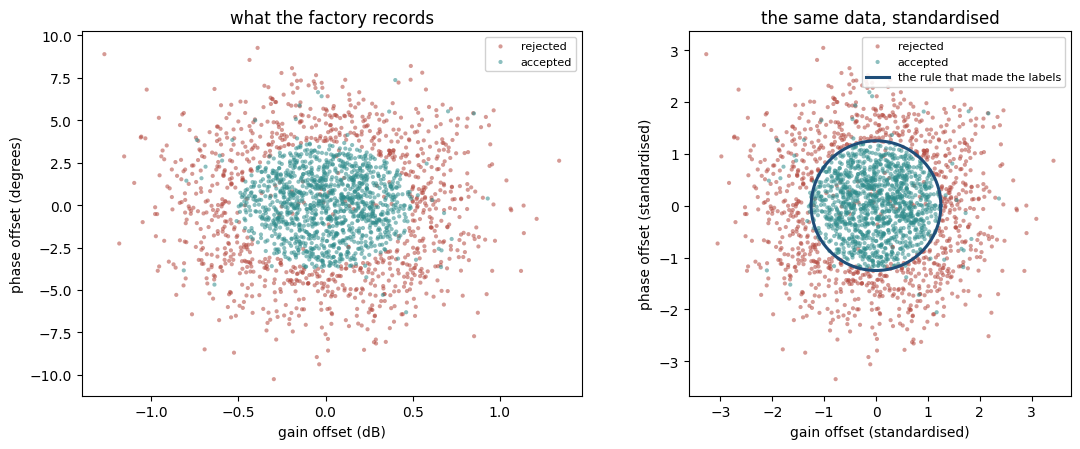

In [2]:
X = units[["gain_offset_db", "phase_offset_deg"]].values
y = units["accepted"].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.25, stratify=y,
                                          random_state=9101)
scaler = StandardScaler().fit(X_tr)
Z_tr, Z_te = scaler.transform(X_tr), scaler.transform(X_te)
print(f"train {Z_tr.shape}   test {Z_te.shape}")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6))
for ax, data, xlabel, ylabel, title in (
        (axes[0], X_tr, "gain offset (dB)", "phase offset (degrees)",
         "what the factory records"),
        (axes[1], Z_tr, "gain offset (standardised)", "phase offset (standardised)",
         "the same data, standardised")):
    for label, colour, name in ((0, RUST, "rejected"), (1, TEAL, "accepted")):
        m = y_tr == label
        ax.scatter(data[m, 0], data[m, 1], s=9, c=colour, alpha=.55,
                   edgecolor="none", label=name)
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
theta = np.linspace(0, 2 * np.pi, 400)
axes[1].plot(TRUE_ACCEPT_RADIUS_SIGMA * np.cos(theta),
             TRUE_ACCEPT_RADIUS_SIGMA * np.sin(theta),
             color=BLUE, lw=2.2, label="the rule that made the labels")
axes[1].set_aspect("equal")
for ax in axes:
    ax.legend(loc="upper right", fontsize=8, framealpha=.9)
fig.tight_layout()
fig.savefig(FIGURES / "acceptance_data.png", dpi=150, bbox_inches="tight")
plt.show()

The right panel shows the rule that generated the labels: once each axis is
divided by its own production spread, a sensor passes when it lies **inside a
circle of radius 1.25**. The few points of the wrong colour scattered along the
circle are the test rig's mistakes: it records 3% of its verdicts the wrong way
round. So even a perfect model would disagree with 3% of the recorded labels,
and **0.97 is the best accuracy anything in this lesson can score**.

## 3. One straight line

Logistic regression is one unit: a weighted sum of the two offsets, plus a
bias, through a sigmoid. Its boundary, where it is undecided at 0.5, is a
straight line.

In [3]:
line_model = LogisticRegression().fit(Z_tr, y_tr)
line_acc = line_model.score(Z_te, y_te)
majority = max(y_te.mean(), 1 - y_te.mean())
print(f"always predict 'accepted'       : {majority:.4f}")
print(f"logistic regression (one line)  : {line_acc:.4f}")
print(f"the rig's ceiling               : {1 - TRUE_RIG_ERROR_RATE:.4f}")

always predict 'accepted'       : 0.5480
logistic regression (one line)  : 0.5507
the rig's ceiling               : 0.9700


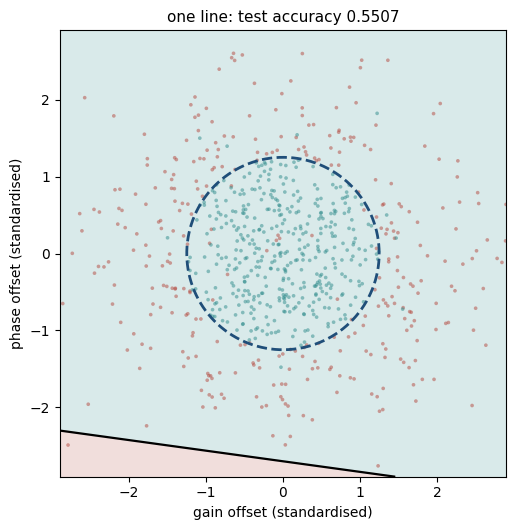

coefficients [[0.0096 0.0701]]  intercept [0.1892]


In [4]:
def plot_boundary(ax, model, Z, labels, title, grid=2.9):
    """Shade where a fitted model says 'accepted', with the points on top."""
    g = np.linspace(-grid, grid, 300)
    G1, G2 = np.meshgrid(g, g)
    P = model.predict_proba(np.c_[G1.ravel(), G2.ravel()])[:, 1].reshape(G1.shape)
    ax.contourf(G1, G2, P, levels=[0, 0.5, 1], colors=[RUST, TEAL], alpha=.18)
    ax.contour(G1, G2, P, levels=[0.5], colors="black", linewidths=1.6)
    for label, colour in ((0, RUST), (1, TEAL)):
        m = labels == label
        ax.scatter(Z[m, 0], Z[m, 1], s=7, c=colour, alpha=.5, edgecolor="none")
    ax.set_title(title, fontsize=11)
    ax.set_xlim(-grid, grid); ax.set_ylim(-grid, grid)
    ax.set_aspect("equal")


fig, ax = plt.subplots(figsize=(5.6, 5.4))
plot_boundary(ax, line_model, Z_te, y_te,
              f"one line: test accuracy {line_acc:.4f}")
ax.plot(TRUE_ACCEPT_RADIUS_SIGMA * np.cos(theta),
        TRUE_ACCEPT_RADIUS_SIGMA * np.sin(theta), color=BLUE, lw=2, ls="--")
ax.set_xlabel("gain offset (standardised)"); ax.set_ylabel("phase offset (standardised)")
fig.tight_layout()
fig.savefig(FIGURES / "linear_boundary_fails.png", dpi=150, bbox_inches="tight")
plt.show()
print("coefficients", line_model.coef_.round(4), " intercept", line_model.intercept_.round(4))

The line scores almost exactly what "always say accepted" scores. The fit did
not fail: the accept region is a disc centred on the origin, so whatever a line
gains by tilting one way it gives back on the opposite side, and the best it can
do is barely tilt at all. **No straight line can enclose a region.**

## 4. One unit, computed by hand

Before any library: what one unit computes, in five lines of NumPy. The weights
are the ones drawn on the lesson's single-neuron slide, $w_1 = 1$, $w_2 = 2$,
$b = -1$.

In [5]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

w, b = np.array([1.0, 2.0]), -1.0
points = np.array([[0.0, 0.0], [1.0, 0.0], [1.0, 1.0], [-1.0, 0.5]])
z = points @ w + b                      # the weighted sum, one per point
y_hat = sigmoid(z)                      # squashed between 0 and 1
for p, zi, yi in zip(points, z, y_hat):
    verdict = "undecided" if zi == 0 else f"says {int(zi > 0)}"
    print(f"x = {p}   z = {zi:+.1f}   y-hat = {yi:.4f}   {verdict}")

x = [0. 0.]   z = -1.0   y-hat = 0.2689   says 0
x = [1. 0.]   z = +0.0   y-hat = 0.5000   undecided
x = [1. 1.]   z = +2.0   y-hat = 0.8808   says 1
x = [-1.   0.5]   z = -1.0   y-hat = 0.2689   says 0


The point $(1, 0)$ gives $z = 0$ and $\hat{y} = 0.5$ exactly: it sits on the
unit's line $x_1 + 2x_2 - 1 = 0$. Every point is classified by which side of
that one line it falls on.

## 5. The drift problem, and a network written down by hand

Each unit of the second problem has two drifts, $a$ and $b$, in millivolts. It
is correctable when they share a sign.

In [6]:
drift = make_channel_drift()
D = drift[["drift_a_mv", "drift_b_mv"]].values
d = drift["correctable"].values
print(f"{len(drift)} units, {d.mean():.2f} correctable")
print(f"logistic regression (one line): {LogisticRegression().fit(D, d).score(D, d):.4f}")

800 units, 0.50 correctable
logistic regression (one line): 0.5000


A line scores exactly 0.5: it is worth nothing. But two hidden units are
enough, and here are weights chosen by hand. Both correctable clouds have
$a + b$ near $+2$ or $-2$, both uncorrectable ones near 0, so the rule is
"$|a + b|$ is large". Hidden unit 1 fires when $a + b > 1$, hidden unit 2 when
$a + b < -1$; each is a ReLU, $\mathrm{ReLU}(z) = \max(0, z)$. The output unit
adds them up and puts the sum through a sigmoid.

In [7]:
def relu(z):
    return np.maximum(0, z)

W1 = np.array([[1.0, -1.0],             # column 1: unit 1 sees a + b
               [1.0, -1.0]])            # column 2: unit 2 sees -a - b
b1 = np.array([-1.0, -1.0])
W2 = np.array([10.0, 10.0])
b2 = -1.0

hidden = relu(D @ W1 + b1)              # the forward pass, in two lines
y_hat = sigmoid(hidden @ W2 + b2)
hand_acc = ((y_hat > 0.5) == d).mean()
print(f"hand-built two-unit network on all {len(drift)} units: {hand_acc:.4f}")

hand-built two-unit network on all 800 units: 0.9938


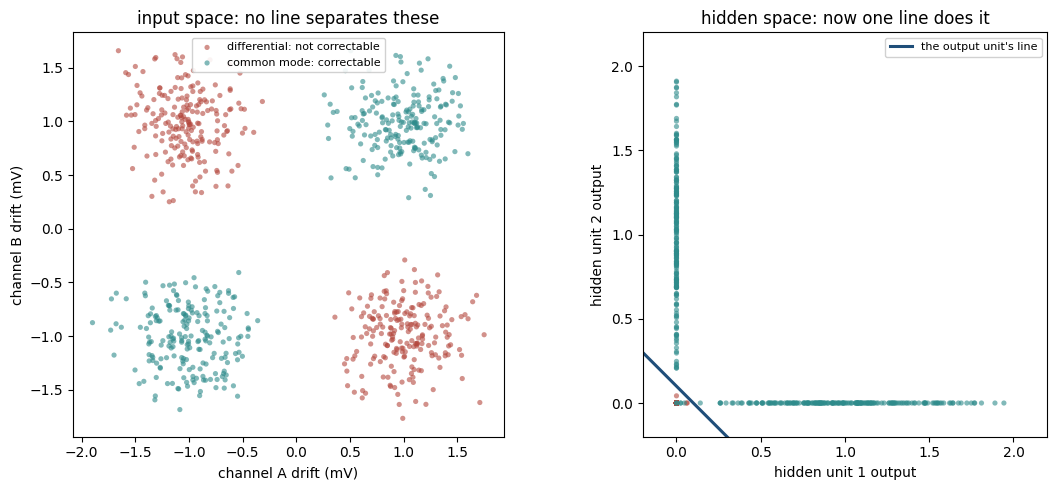

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.0))
ax = axes[0]
for label, colour, name in ((0, RUST, "differential: not correctable"),
                            (1, TEAL, "common mode: correctable")):
    m = d == label
    ax.scatter(D[m, 0], D[m, 1], s=14, c=colour, alpha=.6, edgecolor="none", label=name)
ax.set_xlabel("channel A drift (mV)"); ax.set_ylabel("channel B drift (mV)")
ax.set_title("input space: no line separates these")
ax.legend(loc="upper center", fontsize=8, framealpha=.9)
ax.set_aspect("equal")
ax = axes[1]
for label, colour in ((0, RUST), (1, TEAL)):
    m = d == label
    ax.scatter(hidden[m, 0], hidden[m, 1], s=14, c=colour, alpha=.6, edgecolor="none")
edge = np.linspace(-0.2, 2.2, 10)
ax.plot(edge, 0.1 - edge, color=BLUE, lw=2.2, label="the output unit's line")
ax.set_xlabel("hidden unit 1 output"); ax.set_ylabel("hidden unit 2 output")
ax.set_title("hidden space: now one line does it")
ax.legend(loc="upper right", fontsize=8, framealpha=.9)
ax.set_xlim(-0.2, 2.2); ax.set_ylim(-0.2, 2.2); ax.set_aspect("equal")
fig.tight_layout()
fig.savefig(FIGURES / "xor_hidden_space.png", dpi=150, bbox_inches="tight")
plt.show()

The hidden layer classified nothing. It **moved the data**: the two
correctable clouds land at $(1, 0)$ and $(0, 1)$, both uncorrectable clouds on
top of each other at the origin, and in those new coordinates a single line
separates them. That is the whole idea of a hidden layer.

## 6. Letting training find the weights

Nobody writes weights by hand in practice. scikit-learn's `MLPClassifier`
(multilayer perceptron) trains a network with one hidden layer of the size
you ask for. Twenty training runs per size, each from a different random
starting point (`random_state`), all scored on the same 800 units.

In [9]:
rows = []
models = {}
for width in (2, 4, 8):
    scores = []
    for seed in range(20):
        net = MLPClassifier(hidden_layer_sizes=(width,), max_iter=3000,
                            random_state=seed).fit(D, d)
        scores.append(net.score(D, d))
        models[(width, seed)] = net
    rows.append({"hidden units": width, "runs reaching 0.99": sum(s > 0.99 for s in scores),
                 "of": len(scores), "median accuracy": np.median(scores)})
pd.DataFrame(rows).set_index("hidden units").round(4)

,runs reaching 0.99,of,median accuracy
hidden units,,,
2,6,20,0.7381
4,17,20,1.0000
8,20,20,1.0000


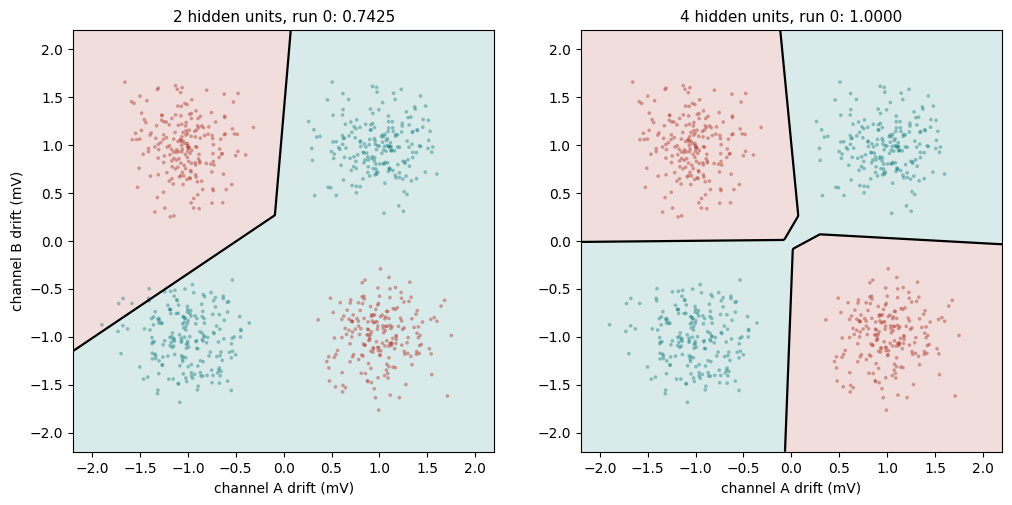

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 5.0))
plot_boundary(axes[0], models[(2, 0)], D, d,
              f"2 hidden units, run 0: {models[(2, 0)].score(D, d):.4f}", grid=2.2)
plot_boundary(axes[1], models[(4, 0)], D, d,
              f"4 hidden units, run 0: {models[(4, 0)].score(D, d):.4f}", grid=2.2)
for ax in axes:
    ax.set_xlabel("channel A drift (mV)")
axes[0].set_ylabel("channel B drift (mV)")
fig.tight_layout()
fig.savefig(FIGURES / "drift_boundaries.png", dpi=150, bbox_inches="tight")
plt.show()

Two hidden units *can* solve the problem (the hand-built network just did),
but training from a random start finds that solution in only a minority of
runs; most settle on walling off three of the four clouds, about 0.74. With
four units most runs succeed, and with eight all twenty do. A wider layer than
the problem strictly needs gives training more chances to start near a good set
of lines, which is why networks used in practice are wider than their task
requires.

## 7. Back to the acceptance test: how many hidden units?

Each hidden unit draws one line. One line cannot enclose the circle; a few,
combined by the output unit, can. Five runs per width, scored on the 750 test
sensors.

In [11]:
widths = (1, 2, 3, 4, 8, 16)
width_rows, nets = [], {}
for width in widths:
    scores = []
    for seed in range(5):
        net = MLPClassifier(hidden_layer_sizes=(width,), max_iter=3000,
                            random_state=seed).fit(Z_tr, y_tr)
        scores.append(net.score(Z_te, y_te))
        nets[(width, seed)] = net
    width_rows.append({"hidden units": width, "mean test accuracy": np.mean(scores),
                       "worst of 5": min(scores), "best of 5": max(scores)})
width_table = pd.DataFrame(width_rows).set_index("hidden units")
width_table.round(4)

,mean test accuracy,worst of 5,best of 5
hidden units,,,
1,0.6048,0.5480,0.6493
2,0.7392,0.7240,0.7693
3,0.8120,0.7227,0.9160
4,0.8821,0.7227,0.9507
8,0.9445,0.9387,0.9493
16,0.9549,0.9520,0.9600


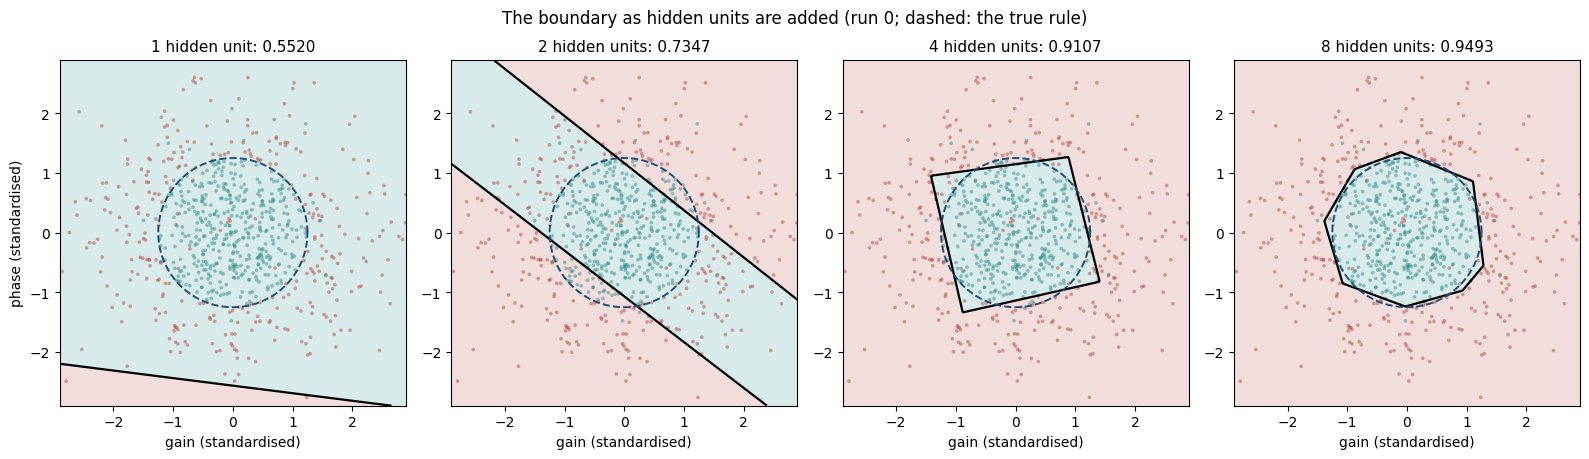

In [12]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, width in zip(axes, (1, 2, 4, 8)):
    net = nets[(width, 0)]
    plot_boundary(ax, net, Z_te, y_te,
                  f"{width} hidden unit{'s' if width > 1 else ''}: "
                  f"{net.score(Z_te, y_te):.4f}")
    ax.plot(TRUE_ACCEPT_RADIUS_SIGMA * np.cos(theta),
            TRUE_ACCEPT_RADIUS_SIGMA * np.sin(theta), color=BLUE, lw=1.4, ls="--")
    ax.set_xlabel("gain (standardised)")
axes[0].set_ylabel("phase (standardised)")
fig.suptitle("The boundary as hidden units are added (run 0; dashed: the true rule)",
             fontsize=12)
fig.tight_layout()
fig.savefig(FIGURES / "boundaries_by_width.png", dpi=150, bbox_inches="tight")
plt.show()

### Each hidden unit is a line

The weights of hidden unit $j$ are column $j$ of the first weight matrix,
`coefs_[0]`, and its bias is `intercepts_[0][j]`. The line where that unit's
weighted sum is zero can be drawn straight from them.

first weight matrix: shape (2, 8) - one column per hidden unit


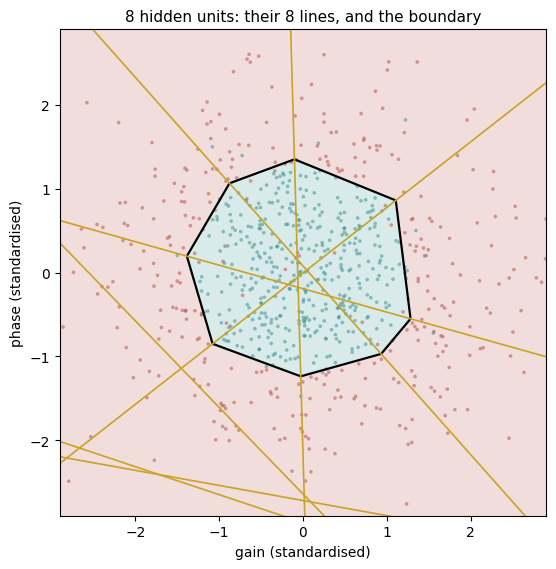

In [13]:
net = nets[(8, 0)]
W, bias = net.coefs_[0], net.intercepts_[0]
print("first weight matrix: shape", W.shape, "- one column per hidden unit")

fig, ax = plt.subplots(figsize=(6.0, 5.8))
plot_boundary(ax, net, Z_te, y_te, "8 hidden units: their 8 lines, and the boundary")
g = np.linspace(-2.9, 2.9, 50)
for j in range(W.shape[1]):
    w1, w2 = W[:, j]
    if abs(w2) > abs(w1):
        ax.plot(g, -(w1 * g + bias[j]) / w2, color=GOLD, lw=1.2)
    else:
        ax.plot(-(w2 * g + bias[j]) / w1, g, color=GOLD, lw=1.2)
ax.set_xlabel("gain (standardised)"); ax.set_ylabel("phase (standardised)")
fig.tight_layout()
fig.savefig(FIGURES / "hidden_lines.png", dpi=150, bbox_inches="tight")
plt.show()

The gold lines are the eight hidden units; the black curve is what the output
unit makes of them. Each line on its own cuts the plane in two, as one unit
always does. The output unit's weighted vote over *which side of each line a
point is on* is what bends the boundary into a closed shape.

## 8. What the hidden layer was worth here

In [14]:
net_acc = width_table.loc[8, "mean test accuracy"]
print(f"one line (logistic regression)      : {line_acc:.4f}")
print(f"8 hidden units, mean of 5 runs      : {net_acc:.4f}")
print(f"what the hidden layer was worth     : {100 * (net_acc - line_acc):.1f} points")
print(f"the rig's ceiling                   : {1 - TRUE_RIG_ERROR_RATE:.4f}")

one line (logistic regression)      : 0.5507
8 hidden units, mean of 5 runs      : 0.9445
what the hidden layer was worth     : 39.4 points
the rig's ceiling                   : 0.9700


About **39 points**, on a problem where the answer depends on the two
measurements *together*. Notebook 02 measures the same thing on handwritten
digits, where it turns out to be worth far less: that comparison is the number
this lesson asks you to remember.

## Summary

- One unit is one straight line: it scores 0.55 on the acceptance test and
  0.50 on the drift problem, whatever the optimiser does.
- A hidden layer **moves the data** into coordinates where a line is enough;
  two ReLU units written by hand solve the drift problem.
- Training finds such weights more reliably as the layer widens: on the drift
  problem, more runs succeed at four units than at two, and all of them at
  eight; eight units reached about 0.94 on the acceptance test, against a
  ceiling of 0.97.
- Each hidden unit is a line, and the output unit votes over them.